# CV editor evaluation: analysis of an evaluation round

This notebook reads one or more evaluation rounds (the run folders `evals/run_matrix.py` writes and
`evals/results/<date>/` publishes) and answers two questions:

1. **Is the multi-agent app worth its complexity compared with one strong model call?** Arms are
   *system x writer model*: the multi-agent app (`multi_agent`) with `gpt-6-luna` or `gpt-6.1-terra`, and
   the single-prompt baseline (`single_prompt`, `evals/single_prompt.py`) with luna, terra or `gpt-6.1-sol`.
2. **How good and how safe are the CVs?** In the agreed order: truthfulness (no invented claims) first,
   then fit to the ad, then layout; cost and speed break ties.

It makes **no model calls** and runs offline from top to bottom. As demo data it uses the published
round `evals/results/2026-11-10/` (110 sessions), which has only two arms, multi-agent luna and
multi-agent terra, graded once each by `gpt-6.1-sol`. Sections that need data this round does not have
(single-prompt arms, re-gradings, a second grader) say so and are skipped; their code paths are covered
by `tests/test_analysis_load.py`.

**Run:** `uv run --group analysis jupyter execute --inplace evals/analysis/analysis.ipynb` from the
repository root. Figures and tables go to `evals/analysis/output/<label>/`. To analyse a new round,
change `ROUNDS` and `LABEL` in the parameter cell below (several folders can be combined, e.g. the main
round and the single-prompt runs folder).

In [1]:
import json
import math
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file() and (p / "evals").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from evals.analysis import load, stats

%matplotlib inline
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## Parameters

Everything below is driven by these values. `CONTRASTS` are the planned comparisons, written as
`(A, B)`, and every difference is **B minus A**. The first four are the *primary* family: the blog's
claims rest on them, and their p-values are Holm-adjusted together over all four (a contrast not
run counts as p = 1). The rest are secondary and reported
with confidence intervals only.

In [2]:
LABEL = "2026-11-10"                                   # names the output folder
ROUNDS = [ROOT / "evals" / "results" / "2026-11-10"]   # round folders or runs folders; several are combined
OUT = ROOT / "evals" / "analysis" / "output" / LABEL
FIG, TAB = OUT / "figures", OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

MA_LUNA, MA_TERRA = "multi_agent/gpt-6-luna", "multi_agent/gpt-6.1-terra"
SP_LUNA, SP_TERRA, SP_SOL = "single_prompt/gpt-6-luna", "single_prompt/gpt-6.1-terra", "single_prompt/gpt-6.1-sol"
ARM_ORDER = [MA_LUNA, MA_TERRA, SP_LUNA, SP_TERRA, SP_SOL]
ARM_LABEL = {MA_LUNA: "MA luna", MA_TERRA: "MA terra", SP_LUNA: "SP luna", SP_TERRA: "SP terra", SP_SOL: "SP sol"}
ARM_COLOR = {MA_LUNA: "#1f77b4", MA_TERRA: "#ff7f0e", SP_LUNA: "#9ecae1", SP_TERRA: "#fdae6b", SP_SOL: "#2ca02c"}

CONTRASTS = [  # (A, B, question, primary?)
    (MA_LUNA, SP_LUNA, "architecture, writer fixed at luna: does the app beat one luna call?", True),
    (MA_TERRA, SP_TERRA, "architecture, writer fixed at terra: does the app beat one terra call?", True),
    (MA_LUNA, MA_TERRA, "writer model inside the app: is terra worth 3x the session cost?", True),
    (MA_LUNA, SP_SOL, "can one strong call replace the cheap app?", True),
    (MA_TERRA, SP_SOL, "one strong call vs the app on its better writer", False),
    (SP_LUNA, SP_TERRA, "model scaling in a single call (luna to terra)", False),
    (SP_TERRA, SP_SOL, "model scaling in a single call (terra to sol)", False),
]

# Outcome measures in the agreed priority order. Scores are 0-10 from the grader; counts per session.
TRUTH = ["invented_content_score", "any_unsupported", "n_unsupported", "n_partly"]
FIT = ["fit", "completeness_score"]
LAYOUT = ["visual_layout"]
OTHER = ["overall_score", "cv_standards", "cover_letter", "language_quality", "additional_information", "work_arrangement"]
ATS = ["ats"]   # the grader's one ATS score (0-10); rounds graded before it have none
COST = ["session_usd", "llm_calls", "session_minutes"]
SCORE_METRICS = ["overall_score", "invented_content_score", "fit", "completeness_score", "visual_layout",
                 "cv_standards", "cover_letter", "language_quality", "additional_information", "work_arrangement"]
PRIMARY_METRICS = ["invented_content_score", "fit", "visual_layout", "overall_score"]
# The pre-registered primary grader (plan section 4), by name, never chosen from the data. The demo round
# 2026-11-10 was graded by gpt-6.1-sol only.
PRIMARY_GRADER = "gpt-6.1-sol" if LABEL == "2026-11-10" else "claude-sonnet-5-5"
SEED = 20261111


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")


def label(arm):
    return ARM_LABEL.get(arm, arm)

## 1. Loading and pairing

**Unit of analysis.** One row per *grading* is read from every run folder (`manifest.json`,
`summary.json`, `evaluation/<name>/evaluation.json`); `results.csv` is only used as a cross-check,
because it has no grader name and no room for re-gradings or a second grader. Sessions interrupted for
lack of credit are left out.

**Arms** come from the manifest: `method` (`single_prompt` from `evals/single_prompt.py`, else
`multi_agent`) and the writer model label.

**Pairing.** Two sessions are comparable when they share a *cell*: persona, ad, input set, scripted
user and stated work preference. Arms are compared **within cells** (a paired design), because the
differences between cells (a weak-fit persona, notes-only input) are far larger than the differences
between arms; pairing removes them. Within a cell:

- re-gradings of one session by the same grader are averaged first (they measure the grader, not the
  writer);
- repeats of one arm (rep 1, 2, ...) are averaged next, so **every cell counts once** whatever its
  number of repeats. Treating repeats as extra pairs would overstate the sample size: they share the
  persona, ad and inputs. The spread *between* repeats is used separately as the noise floor (section 5);
- a cell that only one arm of a contrast has is **left out of that contrast** and listed. Nothing is
  imputed: the missing cells are not missing at random (the single-prompt matrix has no scripted users,
  the main matrix runs `notes_only` only on luna), so imputing would mix composition into the comparison.

In [3]:
rows = load.read_rows(*ROUNDS)
df = pd.DataFrame(rows)
graders = df["grader"].replace("", np.nan).dropna().value_counts()
GRADER = PRIMARY_GRADER
if GRADER not in graders.index:
    print(f"WARNING: no gradings by the primary grader {GRADER} in this data")
arms = [a for a in ARM_ORDER if a in set(df["arm"])] + sorted(set(df["arm"]) - set(ARM_ORDER))
print(f"{df['run_id'].nunique()} sessions, {len(df)} gradings; graders: {dict(graders)}; primary grader: {GRADER}")
print("arms present:", [label(a) for a in arms])

# sessions per arm, cells per arm, repeats, gradings per session
sess = df.drop_duplicates("run_id")
# Pilot gate (finding 1c): single-prompt answers that did not parse or were cut off (finish_reason "length").
# Above 5% of the single-prompt sessions, the captain chooses between the strict one-call rule and a bounded re-ask.
sp = sess[sess["method"] == "single_prompt"]
if len(sp):
    bad = sp[sp["failure"] == "parse_error"]
    print(f"single-prompt answers not parsed or cut off: {len(bad)} of {len(sp)} ({len(bad) / len(sp):.0%}; gate 5%); "
          f"finish reasons: {dict(sp['finish_reason'].replace('', 'none').value_counts())}")
degraded = sess[sess["degraded"] != ""]
print(f"app sessions that completed without company research or a fact check: {len(degraded)}"
      + (f" ({dict(degraded['degraded'].value_counts())})" if len(degraded) else ""))
per_arm = sess.groupby("arm").agg(sessions=("run_id", "size"), cells=("case", lambda s: s.nunique()),
                                  max_rep=("rep", "max"))
per_arm["gradings_per_session"] = df.groupby("arm")["run_id"].size() / per_arm["sessions"]
per_arm.index = per_arm.index.map(label)
per_arm

110 sessions, 110 gradings; graders: {'gpt-6.1-sol': np.int64(110)}; primary grader: gpt-6.1-sol
arms present: ['MA luna', 'MA terra']
app sessions that completed without company research or a fact check: 0


,sessions,cells,max_rep,gradings_per_session
arm,,,,
MA luna,78,74,2,1.0
MA terra,32,30,2,1.0


In [4]:
# Cross-check against the published results.csv (same scores for every run), when there is one.
for r in ROUNDS:
    csv_path = Path(r) / "results.csv"
    if csv_path.is_file():
        pub = pd.DataFrame(load.read_results_csv(csv_path)).set_index("run_id")
        ours = df[df["eval_name"] == "eval1"].set_index("run_id")
        cols = ["overall_score", "invented_content_score", "fit", "visual_layout", "session_usd"]
        bad = [(run, c) for run in pub.index for c in cols
               if run in ours.index and pub.at[run, c] != "" and not math.isclose(float(pub.at[run, c]), float(ours.at[run, c]))]
        print(f"{csv_path.relative_to(ROOT)}: {len(pub)} rows, {len(set(pub.index) & set(ours.index))} matched, mismatches: {bad or 'none'}")

evals/results/2026-11-10/results.csv: 110 rows, 110 matched, mismatches: none


In [5]:
# Which cells each arm has: the comparable core is where all present arms meet.
cells = sess.assign(cell=sess.apply(load.cell_of, axis=1))
cell_arms = cells.groupby("cell")["arm"].agg(lambda s: frozenset(s))
common = [c for c, a in cell_arms.items() if set(arms) <= a]
print(f"{len(cell_arms)} cells in total; {len(common)} cells have every present arm (the comparable core)")
for a, b, question, primary in CONTRASTS:
    if a in arms and b in arms:
        p = load.pair_arms(rows, a, b, "overall_score", GRADER)
        print(f"  {label(b)} - {label(a)}: {len(p['pairs'])} pairs; {len(p['only_a'])} cells only {label(a)}, "
              f"{len(p['only_b'])} only {label(b)}")
    else:
        print(f"  {label(b)} - {label(a)}: not in this data ({question})")
core = df[df.apply(lambda r: load.cell_of(r) in set(common), axis=1)]
core_g = core[core["grader"] == GRADER]
core.groupby(["arm", "input_set", "script"]).size().unstack(fill_value=0).rename(index=label)

85 cells in total; 19 cells have every present arm (the comparable core)
  SP luna - MA luna: not in this data (architecture, writer fixed at luna: does the app beat one luna call?)
  SP terra - MA terra: not in this data (architecture, writer fixed at terra: does the app beat one terra call?)
  MA terra - MA luna: 19 pairs; 55 cells only MA luna, 11 only MA terra
  SP sol - MA luna: not in this data (can one strong call replace the cheap app?)
  SP sol - MA terra: not in this data (one strong call vs the app on its better writer)
  SP terra - SP luna: not in this data (model scaling in a single call (luna to terra))
  SP sol - SP terra: not in this data (model scaling in a single call (terra to sol))


script               default  trap-p03
arm      input_set                    
MA luna  all4             15         1
         cv_only           4         0
         no_cv             2         0
         notes_only        1         0
MA terra all4             13         1
         cv_only           4         0
         no_cv             2         0
         notes_only        1         0

## 2. Score distributions by arm

Grades are integers 0-10 and bunch at 7-9, so means hide the shape. The plot shows, per dimension and
arm, every session as a dot (jittered) with the mean and a bootstrap 95% CI. **Only the comparable
core** is plotted: arms with different case mixes (e.g. `notes_only` exists only for luna) would compare
composition, not systems. The table below gives the means on the core and, for reference, on every
session of each arm.

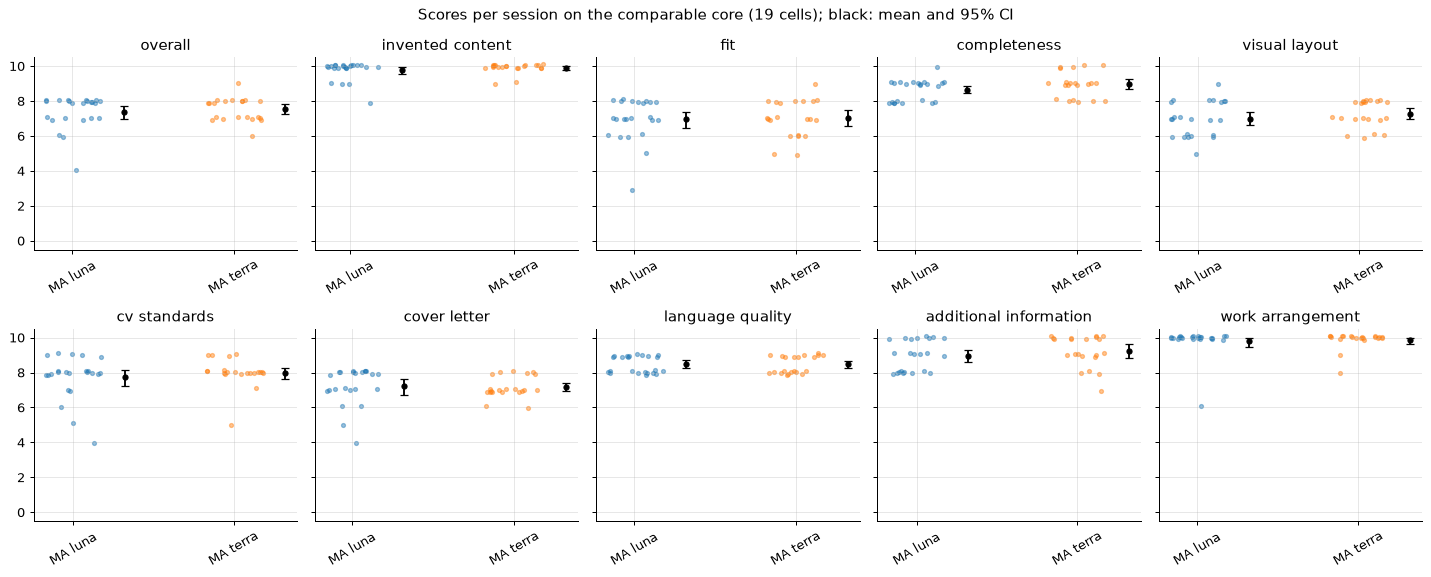

In [6]:
def run_level(frame, metric):
    """One value per session: the mean over the primary grader's gradings."""
    f = frame[frame["grader"] == GRADER] if GRADER else frame
    return f.groupby(["arm", "run_id"])[metric].mean().dropna().reset_index()


fig, axes = plt.subplots(2, 5, figsize=(16, 6.5), sharey=True)
rng = np.random.default_rng(SEED)
for ax, m in zip(axes.flat, SCORE_METRICS):
    data = run_level(core, m)
    for i, arm in enumerate(arms):
        v = data.loc[data["arm"] == arm, m].to_numpy()
        if not len(v):
            continue
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v + rng.uniform(-0.12, 0.12, len(v)), s=10, alpha=0.45,
                   color=ARM_COLOR.get(arm, "gray"))
        mean, lo, hi = stats.bootstrap_mean_ci(v, seed=SEED)
        ax.errorbar(i + 0.32, mean, yerr=[[mean - lo], [hi - mean]], fmt="o", color="black", ms=4, capsize=3)
    ax.set_title(m.replace("_score", "").replace("_", " "))
    ax.set_xticks(range(len(arms)), [label(a) for a in arms], rotation=30)
    ax.set_ylim(-0.5, 10.5)
fig.suptitle(f"Scores per session on the comparable core ({len(common)} cells); black: mean and 95% CI")
fig.tight_layout()
save(fig, "01_score_distributions")

In [7]:
means = pd.concat({
    "core": core_g.groupby("arm")[SCORE_METRICS + ["n_unsupported"]].mean(),
    "all sessions": df[df["grader"] == GRADER].groupby("arm")[SCORE_METRICS + ["n_unsupported"]].mean(),
}).rename(index=label)
means.to_csv(TAB / "means_by_arm.csv")
means.T

core          all sessions         
arm                    MA luna MA terra      MA luna MA terra
overall_score            7.391    7.524        7.321    7.469
invented_content_score   9.783    9.905        9.667    9.875
fit                      6.957    7.048        6.962    7.000
completeness_score       8.652    8.952        8.423    8.844
visual_layout            7.000    7.286        6.872    7.312
cv_standards             7.739    8.000        7.667    8.000
cover_letter             7.217    7.190        7.115    7.031
language_quality         8.478    8.476        8.333    8.156
additional_information   8.957    9.238        8.564    8.719
work_arrangement         9.826    9.857        9.564    9.688
n_unsupported            0.043    0.000        0.090    0.031

## 3. Truthfulness: invented claims

Truthfulness comes first, and its natural measure is a *rate*, not a 0-10 grade. Two rates are shown
per arm, both on the comparable core:

- **sessions with at least one unsupported claim** in the final CV or letter (Wilson 95% CI);
- **unsupported claims per 100 claims** the grader checked (claims are clustered in sessions, so the
  CI is a session-level bootstrap of the ratio).

Stretched ("partly supported") claims are shown next to them. These events are rare (7 of 110
sessions in the demo round), so section 8 shows that no affordable design can *test* a small difference
in them; they are reported with CIs and complemented by the deterministic truthfulness traps
(`trap-*` scripts, `evals/score_truth.py`).

,sessions,with_unsupported,share,share_low,share_high,unsupported_per_100_claims,per100_low,per100_high,partly_per_100_claims
arm,,,,,,,,,
MA luna,23,1,0.043,0.008,0.210,0.054,0.0,0.165,0.435
MA terra,21,0,0.000,0.000,0.155,0.000,0.0,0.000,0.115


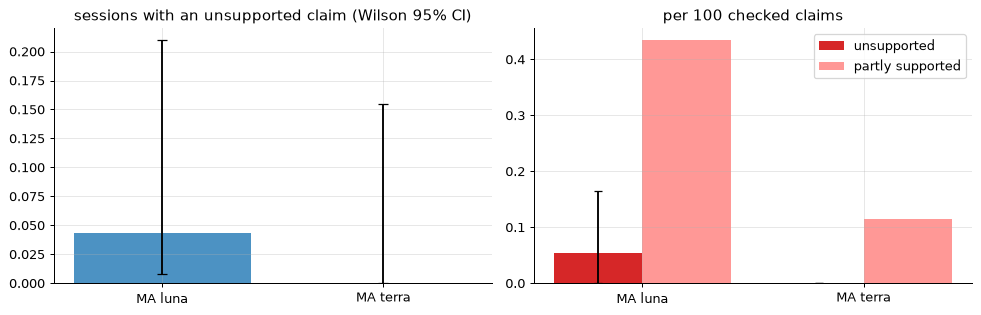

In [8]:
def truth_table(frame):
    out = []
    for arm in arms:
        f = frame[(frame["arm"] == arm)].groupby("run_id")[["any_unsupported", "n_unsupported", "n_partly", "n_claims"]].mean().dropna()
        if f.empty:
            continue
        k, n = int((f["any_unsupported"] > 0).sum()), len(f)
        p, lo, hi = stats.wilson_ci(k, n)
        boot = np.random.default_rng(SEED).integers(0, n, (5000, n))
        u, c, pt = f["n_unsupported"].to_numpy(), f["n_claims"].to_numpy(), f["n_partly"].to_numpy()
        ratio = 100 * u[boot].sum(1) / c[boot].sum(1)
        out.append({"arm": label(arm), "sessions": n, "with_unsupported": k, "share": p, "share_low": lo, "share_high": hi,
                    "unsupported_per_100_claims": 100 * u.sum() / c.sum(), "per100_low": np.quantile(ratio, 0.025),
                    "per100_high": np.quantile(ratio, 0.975), "partly_per_100_claims": 100 * pt.sum() / c.sum()})
    return pd.DataFrame(out).set_index("arm")


truth = truth_table(core_g)
truth.to_csv(TAB / "truthfulness_by_arm.csv")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(truth))
ax1.bar(x, truth["share"], color=[ARM_COLOR.get(a) for a in arms if label(a) in truth.index], alpha=0.8)
ax1.errorbar(x, truth["share"], yerr=[truth["share"] - truth["share_low"], truth["share_high"] - truth["share"]],
             fmt="none", color="black", capsize=4)
ax1.set_xticks(x, truth.index)
ax1.set_title("sessions with an unsupported claim (Wilson 95% CI)")
ax2.bar(x - 0.2, truth["unsupported_per_100_claims"], 0.4, label="unsupported", color="#d62728")
ax2.errorbar(x - 0.2, truth["unsupported_per_100_claims"], fmt="none", color="black", capsize=3,
             yerr=[truth["unsupported_per_100_claims"] - truth["per100_low"], truth["per100_high"] - truth["unsupported_per_100_claims"]])
ax2.bar(x + 0.2, truth["partly_per_100_claims"], 0.4, label="partly supported", color="#ff9896")
ax2.set_xticks(x, truth.index)
ax2.set_title("per 100 checked claims")
ax2.legend()
fig.tight_layout()
save(fig, "02_truthfulness")
truth

### Trap check

Every session of the staged design also gets a trap check (`truth1`, Claude Haiku 5.5, `evals/score_truth.py`):
for each of the persona's deliberate gaps and traps, do the delivered documents (the PDF text) claim the gap as met
or fall into the trap? A session's rate is (gaps claimed + traps hit) / items. Per arm: sessions with a hit
(Wilson 95% CI) and the mean rate. Per contrast: the paired difference of the rate, with the persona-cluster
interval and the persona-level sign-flip test.

In [9]:
trap = pd.DataFrame(load.truth_rows(*ROUNDS))
if trap.empty:
    print("no trap checks in this data")
else:
    trap = trap[trap["eval_name"] == "truth1"]
    trap_arms = []
    for arm in arms:
        f = trap[trap["arm"] == arm].groupby("run_id")["truth_rate"].mean().dropna()
        if f.empty:
            continue
        k, n = int((f > 0).sum()), len(f)
        p, lo, hi = stats.wilson_ci(k, n)
        trap_arms.append({"arm": label(arm), "sessions": n, "with_a_hit": k, "share": p, "share_low": lo,
                          "share_high": hi, "mean_rate": f.mean(),
                          "unverified_quotes": int(trap.loc[trap["arm"] == arm, "unverified_quotes"].sum())})
    trap_pairs = []
    for a, b, question, primary in CONTRASTS:
        pairs = load.pair_arms(trap.to_dict("records"), a, b, "truth_rate")["pairs"] if a in arms and b in arms else []
        if len(pairs) >= 2:
            s = stats.paired_summary([x["diff"] for x in pairs], clusters=[x["persona"] for x in pairs], seed=SEED)
            trap_pairs.append({"contrast": f"{label(b)} - {label(a)}", **{k: s[k] for k in (
                "n_pairs", "mean_diff", "ci_low_cluster", "ci_high_cluster", "p_signflip_cluster")}})
    pd.DataFrame(trap_arms).to_csv(TAB / "trap_check_by_arm.csv", index=False)
    pd.DataFrame(trap_pairs).to_csv(TAB / "trap_check_paired.csv", index=False)
    display(pd.DataFrame(trap_arms))
    display(pd.DataFrame(trap_pairs))

no trap checks in this data


## 4. Paired comparisons between arms

For each planned contrast and measure, the difference B - A is taken per cell and summarised by:

| statistic | why |
|---|---|
| **mean difference with a paired bootstrap 95% CI** (10,000 resamples of cells) | the headline number; no normality assumption, which matters for integer grades with many ties |
| the same CI resampling **whole personas** | cells of one persona are not independent (same candidate, several input sets); if this CI is much wider, the claim rests on few personas |
| **wins / ties / losses** and the exact **sign test** | readable for a blog ("terra better in 6 cells, equal in 9, worse in 4") and assumption-free, but it throws away magnitudes and ties, so it has little power |
| **Wilcoxon signed-rank** (Pratt's handling of zeros) | the main test: uses magnitudes and ranks, robust to the bounded integer scale |
| sign-flip permutation test of the mean | exact for small n; a check on the Wilcoxon result |
| **d_z** = mean / SD of the differences | a standardised effect size for comparison across measures |

**Cells are not independent.** The 39 cells come from 13 personas (three input sets each, one ad per persona),
so the confirmatory test also flips the sign of a whole persona's cells together (`p_signflip_cluster`, exact
over 2^13 = 8,192 sign patterns). A primary claim needs **both** the Wilcoxon test on cells and this
persona-level test (`p_confirm`, the larger of the two).

**Multiple comparisons.** The blog's claims rest on the four primary contrasts and on four primary
measures in the agreed order (invented content, fit, visual layout, overall). `p_confirm` is
**Holm-adjusted over the fixed family of the four primary contrasts within each measure**; a contrast that
was not run counts as p = 1 (not rejected). Secondary contrasts and the other
measures are reported with CIs and labelled exploratory. A mixed model (score ~ arm + (1|persona) +
(1|ad)) would use unpaired cells too, but with 13 personas and 8 ads its random-effect variances are
poorly estimated, and it is harder to explain; it is optional and not needed for the claims here.

**Truthfulness as non-inferiority.** For the architecture contrasts the useful claim is "the cheaper or
simpler system is *not worse* at truthfulness", so its CI is read against a margin (here -0.5 on the
invented-content score): non-inferior when the lower bound of the **persona-cluster** CI is above -0.5.

In [10]:
NI_MARGIN = -0.5
COMPARE = SCORE_METRICS + ["n_unsupported", "n_partly"] + ATS + COST
results = []
for a, b, question, primary in CONTRASTS:
    if a not in arms or b not in arms:
        continue
    for m in COMPARE:
        p = load.pair_arms(rows, a, b, m, GRADER)
        if len(p["pairs"]) < 2:
            continue
        d = [x["diff"] for x in p["pairs"]]
        s = stats.paired_summary(d, clusters=[x["persona"] for x in p["pairs"]], seed=SEED)
        results.append({"A": label(a), "B": label(b), "contrast": f"{label(b)} - {label(a)}", "primary": primary,
                        "metric": m, **s})
res = pd.DataFrame(results)
PRIMARY_FAMILY = [f"{label(b)} - {label(a)}" for a, b, _, primary in CONTRASTS if primary]
if not res.empty:
    # both tests must reject: Wilcoxon on cells and the sign-flip test on whole personas (no test: p = 1)
    res["p_confirm"] = res[["p_wilcoxon", "p_signflip_cluster"]].astype(float).fillna(1.0).max(axis=1)
    res["p_holm"] = np.nan
    for m in PRIMARY_METRICS:
        sel = res[(res["metric"] == m) & res["primary"]]
        adj = stats.holm({**dict.fromkeys(PRIMARY_FAMILY, 1.0), **dict(zip(sel["contrast"], sel["p_confirm"]))})
        for i, contrast in zip(sel.index, sel["contrast"]):
            res.loc[i, "p_holm"] = adj[contrast]
    res["non_inferior"] = np.where(res["metric"] == "invented_content_score", res["ci_low_cluster"] > NI_MARGIN, None)
res.to_csv(TAB / "paired_comparisons.csv", index=False)
show = ["contrast", "metric", "n_pairs", "mean_diff", "ci_low", "ci_high", "ci_low_cluster", "ci_high_cluster",
        "wins_b", "ties", "wins_a", "p_sign", "p_wilcoxon", "p_signflip_cluster", "p_confirm", "p_holm", "dz"]
res[show] if not res.empty else "no contrast has two arms in this data"

,contrast,metric,n_pairs,mean_diff,ci_low,ci_high,ci_low_cluster,ci_high_cluster,wins_b,ties,wins_a,p_sign,p_wilcoxon,p_signflip_cluster,p_confirm,p_holm,dz
0,MA terra - MA luna,overall_score,19,0.211,-0.158,0.632,-0.238,0.722,6,9,4,7.539e-01,4.241e-01,5.469e-01,5.469e-01,1.000,0.229
1,MA terra - MA luna,invented_content_score,19,0.079,-0.184,0.368,-0.105,0.278,3,14,2,1.000e+00,6.556e-01,6.250e-01,6.556e-01,1.000,0.125
2,MA terra - MA luna,fit,19,0.184,-0.105,0.500,-0.114,0.571,5,12,2,4.531e-01,2.592e-01,5.000e-01,5.000e-01,1.000,0.266
3,MA terra - MA luna,completeness_score,19,0.395,0.026,0.789,0.079,0.675,9,6,4,2.668e-01,8.583e-02,6.641e-02,8.583e-02,NaN,0.451
4,MA terra - MA luna,visual_layout,19,0.395,-0.105,0.868,-0.146,1.000,10,4,5,3.018e-01,1.377e-01,2.207e-01,2.207e-01,0.883,0.347
5,MA terra - MA luna,cv_standards,19,0.368,-0.053,0.816,-0.114,0.938,7,8,4,5.488e-01,2.046e-01,2.578e-01,2.578e-01,NaN,0.369
6,MA terra - MA luna,cover_letter,19,0.000,-0.421,0.447,-0.455,0.529,6,6,7,1.000e+00,7.871e-01,1.000e+00,1.000e+00,NaN,0.000
7,MA terra - MA luna,language_quality,19,0.000,-0.289,0.289,-0.312,0.350,5,10,4,1.000e+00,8.773e-01,1.000e+00,1.000e+00,NaN,0.000
8,MA terra - MA luna,additional_information,19,0.263,0.000,0.553,0.000,0.500,6,12,1,1.250e-01,6.365e-02,1.250e-01,1.250e-01,NaN,0.417
9,MA terra - MA luna,work_arrangement,19,-0.053,-0.368,0.263,-0.375,0.294,1,16,2,1.000e+00,5.859e-01,1.000e+00,1.000e+00,NaN,-0.075


### Noise floor in the forest plot

Each panel shows the mean paired difference per measure with its 95% CI. The grey band is the
**noise floor**: the 95% range of a mean difference over the same number of cells if the two arms were
*the same system* run twice. It comes from the repeat pairs (section 5): ±1.96·√2·σ_within/√n. A
difference inside the band is indistinguishable from re-running one system; the CI says whether it is
distinguishable from zero.

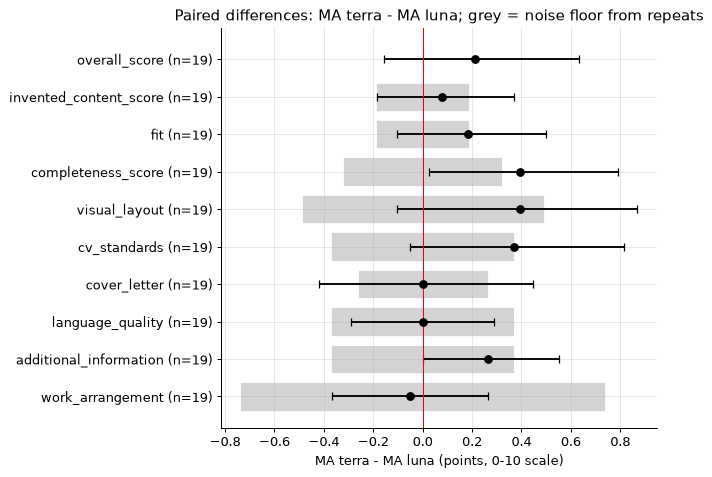

In [11]:
def within_sd(metric):
    groups = [g["values"] for g in load.repeat_groups(rows, metric, GRADER)]
    var, dof = stats.pooled_within_var(groups)
    return math.sqrt(var) if dof else float("nan"), dof


present = res[res["metric"].isin(SCORE_METRICS)] if not res.empty else res
for contrast, sub in (present.groupby("contrast", sort=False) if not present.empty else []):
    fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(sub) + 1.2))
    sub = sub.iloc[::-1]
    y = np.arange(len(sub))
    for yi, (_, r) in zip(y, sub.iterrows()):
        sw, _ = within_sd(r["metric"])
        if not math.isnan(sw):
            half = 1.96 * math.sqrt(2) * sw / math.sqrt(r["n_pairs"])
            ax.fill_betweenx([yi - 0.35, yi + 0.35], -half, half, color="lightgray", zorder=0)
    ax.errorbar(sub["mean_diff"], y, xerr=[sub["mean_diff"] - sub["ci_low"], sub["ci_high"] - sub["mean_diff"]],
                fmt="o", color="black", capsize=3)
    ax.axvline(0, color="red", lw=0.8)
    ax.set_yticks(y, [f"{m} (n={n})" for m, n in zip(sub["metric"], sub["n_pairs"])])
    ax.set_xlabel(f"{contrast} (points, 0-10 scale)")
    ax.set_title(f"Paired differences: {contrast}; grey = noise floor from repeats")
    fig.tight_layout()
    save(fig, "03_forest_" + contrast.replace(" ", "").replace("-", "_minus_"))

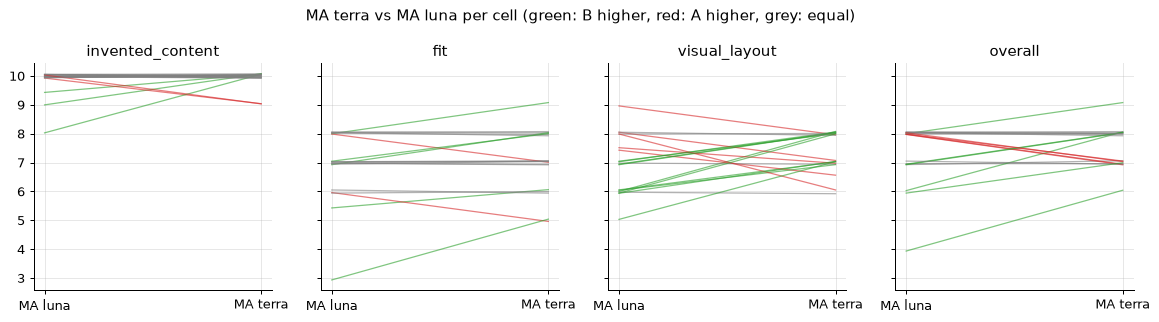

In [12]:
# Every pair for the main measures: one line per cell from A to B (slope chart), jittered for ties.
for a, b, question, primary in CONTRASTS:
    if a not in arms or b not in arms:
        continue
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
    for ax, m in zip(axes, PRIMARY_METRICS):
        pairs = load.pair_arms(rows, a, b, m, GRADER)["pairs"]
        jit = np.random.default_rng(SEED).uniform(-0.08, 0.08, (len(pairs), 2))
        for (pr, j) in zip(pairs, jit):
            c = "#2ca02c" if pr["diff"] > 0 else "#d62728" if pr["diff"] < 0 else "gray"
            ax.plot([0, 1], [pr["a"] + j[0], pr["b"] + j[1]], color=c, alpha=0.6, lw=1)
        ax.set_xticks([0, 1], [label(a), label(b)])
        ax.set_title(m.replace("_score", ""))
    fig.suptitle(f"{label(b)} vs {label(a)} per cell (green: B higher, red: A higher, grey: equal)")
    fig.tight_layout()
    save(fig, f"04_pairs_{label(a)}_vs_{label(b)}".replace(" ", "_"))

## 5. Noise: writer variance and grader variance

Two sources of noise sit on top of real differences between arms:

- **writer variance** σ_writer: the same arm on the same cell produces different documents;
- **grader variance** σ_grader: the same document graded again gets a different grade.

Repeats (rep 1 vs rep 2 of one arm in one cell) measure σ_writer² + σ_grader²/k, where k is the run's
number of gradings (in the staged design run 1 has two Sonnet gradings, eval1 and eval2, and run 2 one).
Re-gradings (`eval1` vs `eval2` of one session by the same grader) measure σ_grader alone. With both,
σ_writer² = σ_within² - mean(1/k)·σ_grader² (`stats.writer_var`). The table gives the components over all
arms and per arm (is the single prompt noisier than the app?). The table also gives **σ_diff**, the SD of the arm-pair
differences across cells: it contains both noises *and* the arm x cell interaction (one arm suits some
personas better), σ_interaction² ≈ σ_diff² - 2σ_within². Which part dominates decides where the next
round's budget goes: interaction is reduced only by **more cells**, writer noise by **repeats**, grader
noise by **re-gradings**.

In [13]:
noise = []
ref = next(((a, b) for a, b, *_ in CONTRASTS if a in arms and b in arms), None)
run_arm = dict(zip(sess["run_id"], sess["arm"]))
for m in SCORE_METRICS + ["n_unsupported", "ats"]:
    all_groups, all_regr = load.repeat_groups(rows, m, GRADER), load.regrade_groups(rows, m, GRADER)
    sd_d = np.nan
    if ref:
        d = [x["diff"] for x in load.pair_arms(rows, *ref, m, GRADER)["pairs"]]
        sd_d = float(np.std(d, ddof=1)) if len(d) >= 2 else np.nan
    for arm in ["all", *arms]:
        groups = [g for g in all_groups if arm in ("all", g["arm"])]
        regr = [g for g in all_regr if arm in ("all", run_arm.get(g["run_id"]))]
        var_w, df_w = stats.pooled_within_var([g["values"] for g in groups])
        lo_w, hi_w = stats.var_ci(var_w, df_w)
        var_g, df_g = stats.pooled_within_var([g["values"] for g in regr])
        var_writer = stats.writer_var([g["values"] for g in groups], [g["k"] for g in groups], var_g if df_g else np.nan)
        noise.append({"metric": m, "arm": "all" if arm == "all" else label(arm), "repeat_groups": len(groups),
                      "df_within": df_w, "sd_within": math.sqrt(var_w) if df_w else np.nan,
                      "sd_within_hi95": math.sqrt(hi_w) if df_w and not math.isnan(hi_w) else np.nan,
                      "regraded_runs": len(regr), "sd_grader": math.sqrt(var_g) if df_g else np.nan,
                      "sd_writer": math.sqrt(var_writer) if not math.isnan(var_writer) else np.nan,
                      "sd_diff_arms": sd_d if arm == "all" else np.nan,
                      "sd_interaction": (math.sqrt(max(0.0, sd_d ** 2 - 2 * var_w))
                                         if arm == "all" and df_w and not np.isnan(sd_d) else np.nan)})
noise = pd.DataFrame(noise).set_index(["metric", "arm"])
noise.to_csv(TAB / "noise_components.csv")
print("reference arm pair for sd_diff_arms:", ref and f"{label(ref[1])} - {label(ref[0])}")
noise

reference arm pair for sd_diff_arms: MA terra - MA luna


repeat_groups  df_within  sd_within  sd_within_hi95  regraded_runs  sd_grader  sd_writer  sd_diff_arms  sd_interaction
metric                 arm                                                                                                                             
overall_score          all                   6          6      0.000           0.000              0        NaN        NaN         0.918           0.918
                       MA luna               4          4      0.000           0.000              0        NaN        NaN           NaN             NaN
                       MA terra              2          2      0.000           0.000              0        NaN        NaN           NaN             NaN
invented_content_score all                   6          6      0.289           0.636              0        NaN        NaN         0.629           0.479
                       MA luna               4          4      0.354           1.016              0        NaN        NaN           NaN             NaN
                       MA terra              2          2      0.000           0.000              0        NaN        NaN           NaN             NaN
fit                    all                   6          6      0.289           0.636              0        NaN        NaN         0.691           0.558
                       MA luna               4          4      0.354           1.016              0        NaN        NaN           NaN             NaN
                       MA terra              2          2      0.000           0.000              0        NaN        NaN           NaN             NaN
completeness_score     all                   6          6      0.500           1.101              0        NaN        NaN         0.875           0.516
                       MA luna               4          4      0.500           1.437              0        NaN        NaN           NaN             NaN
                       MA terra              2          2      0.500           3.142              0        NaN        NaN           NaN             NaN
visual_layout          all                   6          6      0.764           1.682              0        NaN        NaN         1.137           0.357
                       MA luna               4          4      0.500           1.437              0        NaN        NaN           NaN             NaN
                       MA terra              2          2      1.118           7.027              0        NaN        NaN           NaN             NaN
cv_standards           all                   6          6      0.577           1.271              0        NaN        NaN         0.998           0.574
                       MA luna               4          4      0.500           1.437              0        NaN        NaN           NaN             NaN
                       MA terra              2          2      0.707           4.444              0        NaN        NaN           NaN             NaN
cover_letter           all                   6          6      0.408           0.899              0        NaN        NaN         0.986           0.799
                       MA luna               4          4      0.500           1.437              0        NaN        NaN           NaN             NaN
                       MA terra              2          2      0.000           0.000              0        NaN        NaN           NaN             NaN
language_quality       all                   6          6      0.577           1.271              0        NaN        NaN         0.645           0.000
                       MA luna               4          4      0.612           1.760              0        NaN        NaN           NaN             NaN
                       MA terra              2          2      0.500           3.142              0        NaN        NaN           NaN             NaN
additional_information all                   6          6      0.577           1.

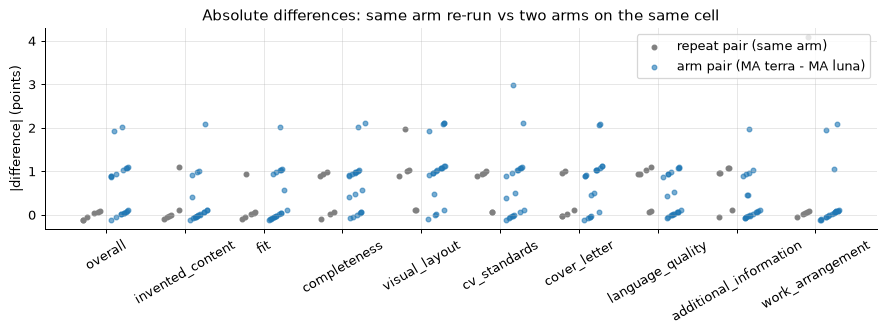

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, m in enumerate(SCORE_METRICS):
    rep = [g["values"][1] - g["values"][0] for g in load.repeat_groups(rows, m, GRADER)]
    arm_d = [x["diff"] for x in load.pair_arms(rows, *ref, m, GRADER)["pairs"]] if ref else []
    j = np.random.default_rng(i).uniform(-0.12, 0.12, max(len(rep), len(arm_d), 1))
    ax.scatter(i - 0.18 + j[:len(rep)], np.abs(rep) + j[:len(rep)], s=14, color="gray", label="repeat pair (same arm)" if i == 0 else None)
    ax.scatter(i + 0.18 + j[:len(arm_d)], np.abs(arm_d) + j[:len(arm_d)], s=14, color="#1f77b4", alpha=0.6,
               label=f"arm pair ({ref and label(ref[1])} - {ref and label(ref[0])})" if i == 0 else None)
ax.set_xticks(range(len(SCORE_METRICS)), [m.replace("_score", "") for m in SCORE_METRICS], rotation=30)
ax.set_ylabel("|difference| (points)")
ax.set_title("Absolute differences: same arm re-run vs two arms on the same cell")
ax.legend(loc="upper right")
fig.tight_layout()
save(fig, "05_noise_floor")

## 6. Where the differences are: input set, ad, persona

Paired differences by input set (the strongest driver of scores in the demo round, `notes_only` far
below the rest) and by persona show whether an arm's advantage is general or confined to some cases.
The descriptive means by ad and persona use **every** session of each arm, so they mix composition;
they describe the round, not a comparison.

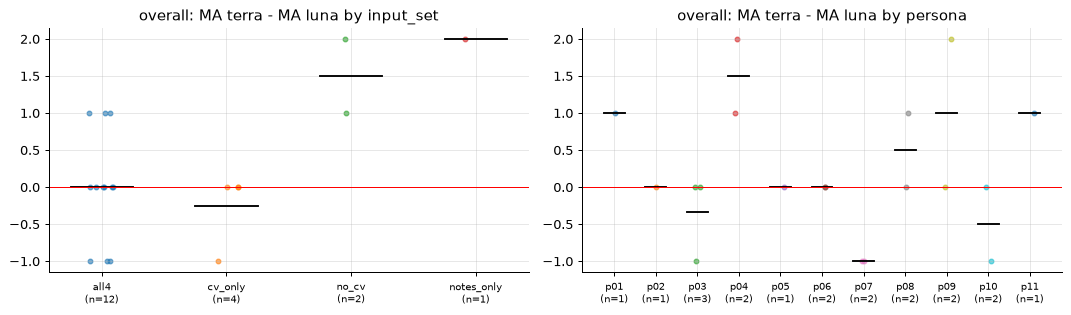

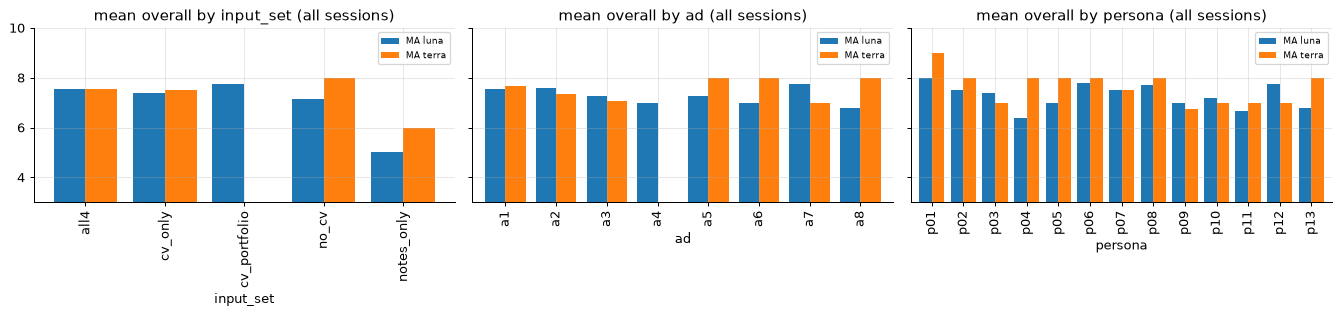

In [15]:
if ref:
    pairs = pd.DataFrame(load.pair_arms(rows, *ref, "overall_score", GRADER)["pairs"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    for ax, by in zip(axes, ["input_set", "persona"]):
        g = pairs.groupby(by)["diff"]
        order = sorted(g.groups)
        for i, k in enumerate(order):
            v = g.get_group(k).to_numpy()
            ax.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-0.1, 0.1, len(v)), v, s=14, alpha=0.6)
            ax.plot([i - 0.25, i + 0.25], [v.mean()] * 2, color="black")
        ax.axhline(0, color="red", lw=0.8)
        ax.set_xticks(range(len(order)), [f"{k}\n(n={len(g.get_group(k))})" for k in order], fontsize=8)
        ax.set_title(f"overall: {label(ref[1])} - {label(ref[0])} by {by}")
    fig.tight_layout()
    save(fig, "06_pair_diffs_by_input_and_persona")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
allg = df[df["grader"] == GRADER]
for ax, by in zip(axes, ["input_set", "ad", "persona"]):
    tab = allg.groupby([by, "arm"])["overall_score"].mean().unstack()
    tab = tab[[a for a in arms if a in tab.columns]]
    tab.rename(columns=label).plot.bar(ax=ax, color=[ARM_COLOR.get(a) for a in tab.columns], width=0.8)
    ax.set_ylim(3, 10)
    ax.set_title(f"mean overall by {by} (all sessions)")
    ax.legend(fontsize=7)
fig.tight_layout()
save(fig, "07_overall_by_input_ad_persona")

## 7. Cost, calls and latency

Cost and speed are tie-breakers. The frontier plot puts each arm's mean session cost (log scale)
against its mean overall score and invented-content score on the comparable core: an arm is worth
considering only if no other arm is both cheaper and better. Grading cost is shown separately because
it is the evaluation's cost, not the product's.

Prices per million tokens are **recovered from the recorded runs** (least squares on each model's
uncached input, cached input and output tokens against its recorded cost), so the cost estimates in
section 8 use the prices the round was actually charged.

In [16]:
cost = sess.groupby("arm").agg(sessions=("run_id", "size"), session_usd=("session_usd", "mean"),
                               calls_median=("llm_calls", "median"), minutes=("session_minutes", "mean"))
cost["grading_usd"] = df.groupby("arm")["eval_usd"].mean()
cost = cost.loc[[a for a in arms if a in cost.index]]
cost.rename(index=label).to_csv(TAB / "cost_by_arm.csv")

usage = pd.DataFrame(load.token_usage(*ROUNDS))
prices = {}
for model, g in usage.groupby("model"):
    X = g[["uncached_in", "cached_in", "output"]].to_numpy(float)
    coef = np.linalg.lstsq(X, g["cost_usd"].to_numpy(float), rcond=None)[0] * 1e6
    prices[model] = {"usd_per_1M_input": round(coef[0], 3), "usd_per_1M_cached_input": round(coef[1], 3),
                     "usd_per_1M_output": round(coef[2], 3), "calls_recorded": len(g),
                     "used_as": "/".join(sorted(g["kind"].unique()))}
prices = pd.DataFrame(prices).T
prices.to_csv(TAB / "token_prices.csv")
display(cost.rename(index=label))
prices

,sessions,session_usd,calls_median,minutes,grading_usd
arm,,,,,
MA luna,78,0.028,23.0,4.105,0.126
MA terra,32,0.088,22.0,3.302,0.123


,usd_per_1M_input,usd_per_1M_cached_input,usd_per_1M_output,calls_recorded,used_as
gpt-5.6-luna,0.2,0.02,1.2,110,session
gpt-6-luna,0.1,0.01,0.5,78,session
gpt-6.1-sol,2.0,0.0,10.0,110,grading
gpt-6.1-terra,1.0,0.1,5.0,32,session


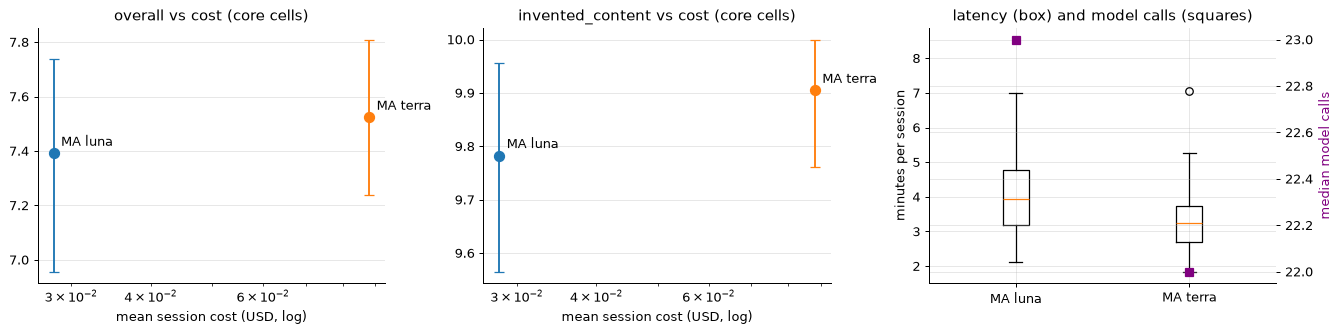

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, m in zip(axes[:2], ["overall_score", "invented_content_score"]):
    for arm in arms:
        v = run_level(core, m)
        v = v.loc[v["arm"] == arm, m].to_numpy()
        if not len(v):
            continue
        mean, lo, hi = stats.bootstrap_mean_ci(v, seed=SEED)
        c = cost.loc[arm, "session_usd"]
        ax.errorbar(c, mean, yerr=[[mean - lo], [hi - mean]], fmt="o", color=ARM_COLOR.get(arm), capsize=4, ms=8)
        ax.annotate(label(arm), (c, mean), textcoords="offset points", xytext=(6, 6))
    ax.set_xscale("log")
    ax.set_xlabel("mean session cost (USD, log)")
    ax.set_title(f"{m.replace('_score', '')} vs cost (core cells)")
d = sess[["arm", "llm_calls", "session_minutes"]]
axes[2].boxplot([d.loc[d["arm"] == a, "session_minutes"].dropna() for a in arms], tick_labels=[label(a) for a in arms])
axes[2].set_ylabel("minutes per session")
ax2 = axes[2].twinx()
ax2.plot(range(1, len(arms) + 1), [d.loc[d["arm"] == a, "llm_calls"].median() for a in arms], "s", color="purple")
ax2.set_ylabel("median model calls", color="purple")
axes[2].set_title("latency (box) and model calls (squares)")
fig.tight_layout()
save(fig, "08_cost_quality_latency")

## 8. ATS-friendliness without cheating

Applicant-tracking systems (ATS) screen on the plain text they pull out of the PDF: its order, its section
headings and the ad's keywords. A writer can match the ad honestly (naming skills the candidate really has in
the ad's words) or by cheating (claiming skills the candidate lacks, or keyword stuffing). The grader judges
this inside its one grading call and gives **one ATS score**, `ats` (0-10, with a short reason). It reads the
text a standard extractor (pdfplumber, no model) pulls from the CV PDF, labelled "what an ATS would read",
next to the page images, and records three judgements behind the score:

| judgement | fields in the grader's `ats` section |
|---|---|
| the extracted text is readable, in order and in clear sections | `text_readable_in_order`, `clear_sections`, `headings_found`, `parse_issues` |
| the ad's important requirements the candidate has are visible in searchable wording | `important_requirements`, `covered_in_searchable_wording`, `missed_but_candidate_has` |
| keyword stuffing or skills the candidate does not have | `keyword_stuffing`, `unsupported_keywords` |

Requirements the candidate lacks cost nothing when they are left out; stuffing and unsupported keywords lower
the score. The analysis reads only the score. The plot checks that high ATS scores do not come with claims the
grader's claim check flags. Rounds graded before this score was added (2026-11-10) have no ATS score.

In [18]:
ats_tab = core_g.groupby("arm")[["ats", "n_unsupported", "n_partly"]].mean().rename(index=label)
ats_tab.to_csv(TAB / "ats_by_arm.csv")
if core_g["ats"].notna().any():
    jitter = np.random.default_rng(1).uniform(-0.1, 0.1, len(core_g))
    fig, ax = plt.subplots(figsize=(6, 4))
    for arm in arms:
        f = core_g[core_g["arm"] == arm]
        ax.scatter(f["ats"] + jitter[: len(f)], f["n_unsupported"] + f["n_partly"] + jitter[: len(f)],
                   s=16, alpha=0.6, color=ARM_COLOR.get(arm), label=label(arm))
    ax.set_xlabel("ATS score (0-10)")
    ax.set_ylabel("unsupported + stretched claims")
    ax.set_title("cheating check: high ATS scores with flagged claims?")
    ax.legend(fontsize=8)
    fig.tight_layout()
    save(fig, "09_ats")
else:
    print("no ATS scores in these rounds: they were graded before the ATS score was added")
ats_tab

no ATS scores in these rounds: they were graded before the ATS score was added


,ats,n_unsupported,n_partly
arm,,,
MA luna,NaN,0.043,0.348
MA terra,NaN,0.000,0.095


## 9. Grader calibration

The grade is a model's judgement, so the blog needs evidence that the conclusions do not depend on the
grader. When the same sessions are graded by two graders (e.g. `gpt-6.1-sol` and an Anthropic model,
each grading stored under its own `evaluation/<name>/`), this section reports per measure:

- **exact agreement** and **agreement within one point**;
- **bias**: mean of grader B - grader A with a bootstrap CI (a constant offset does not change paired
  arm differences, but it changes the reported levels);
- **Spearman and Kendall rank correlation** and **quadratic-weighted kappa** (do they order sessions
  alike?);
- a **Bland-Altman** plot (difference against mean) to see whether disagreement depends on the level;
- and the decisive check: **does each contrast's mean difference and its sign agree under both
  graders?** If two graders agree on the arm differences, a moderate session-level disagreement does
  not matter for the claims.

Re-gradings by the same grader (`eval1`, `eval2`) give its self-agreement, the ceiling for agreement
between graders.

In [19]:
if len(graders) < 2:
    print(f"Only one grader in this data ({', '.join(graders.index) or 'none'}): no calibration possible. "
          "Grade a subset of sessions with a second grader (evals/evaluate.py --model ... --name <grader>1) "
          "and re-run this notebook.")
else:
    ga, gb = graders.index[0], graders.index[1]
    cal = []
    for m in SCORE_METRICS:
        gp = load.grader_pairs(rows, m, ga, gb)
        cal.append({"metric": m, **stats.agreement([x["a"] for x in gp], [x["b"] for x in gp])})
    cal = pd.DataFrame(cal).set_index("metric")
    cal.to_csv(TAB / "grader_agreement.csv")
    display(cal)
    gp = pd.DataFrame(load.grader_pairs(rows, "overall_score", ga, gb))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    j = np.random.default_rng(SEED).uniform(-0.15, 0.15, (len(gp), 2))
    axes[0].scatter(gp["a"] + j[:, 0], gp["b"] + j[:, 1], s=14, alpha=0.6)
    axes[0].plot([0, 10], [0, 10], color="gray")
    axes[0].set_xlabel(ga)
    axes[0].set_ylabel(gb)
    axes[0].set_title("overall: grader vs grader")
    mean_, diff_ = (gp["a"] + gp["b"]) / 2, gp["b"] - gp["a"]
    axes[1].scatter(mean_ + j[:, 0], diff_ + j[:, 1], s=14, alpha=0.6)
    for yv in (diff_.mean(), diff_.mean() + 1.96 * diff_.std(), diff_.mean() - 1.96 * diff_.std()):
        axes[1].axhline(yv, color="gray", ls="--")
    axes[1].set_xlabel("mean of the two grades")
    axes[1].set_ylabel(f"{gb} - {ga}")
    axes[1].set_title("Bland-Altman (overall)")
    fig.tight_layout()
    save(fig, "10_grader_calibration")
    same = []
    for a, b, question, primary in CONTRASTS:
        if a in arms and b in arms:
            for m in PRIMARY_METRICS:
                da = [x["diff"] for x in load.pair_arms(rows, a, b, m, ga)["pairs"]]
                db = [x["diff"] for x in load.pair_arms(rows, a, b, m, gb)["pairs"]]
                if da and db:
                    same.append({"contrast": f"{label(b)} - {label(a)}", "metric": m, f"diff_{ga}": np.mean(da),
                                 f"diff_{gb}": np.mean(db), "same_sign": np.sign(np.mean(da)) == np.sign(np.mean(db))})
    display(pd.DataFrame(same))

regraded = load.regrade_groups(rows, "overall_score")
print(f"sessions graded twice or more by the same grader: {len(regraded)}"
      + ("" if regraded else " (none in this data: no grader self-agreement yet)"))

Only one grader in this data (gpt-6.1-sol): no calibration possible. Grade a subset of sessions with a second grader (evals/evaluate.py --model ... --name <grader>1) and re-run this notebook.
sessions graded twice or more by the same grader: 0 (none in this data: no grader self-agreement yet)


## 10. Power and sample size

How many paired cells, repeats and gradings does the next round need to detect a difference of
**0.5** and **1 point** (0-10 scale) between two arms? The SD of a cell's paired difference is modelled
as

σ_diff² = σ_interaction² + 2σ_writer²/r + 2σ_grader²/(r·k)

with r repeats per arm and cell and k gradings per session. Inputs from the demo round (section 5):

- **σ_diff** observed on the luna-terra pairs, and a **pessimistic** value: the larger of its 80%
  bootstrap upper bound and 1.5x the observed value, because the architecture contrasts (single prompt
  vs app) compare systems that differ more than two writer models inside one app;
- **σ_within** = √(σ_writer² + σ_grader²) from the repeat pairs, with a **floor of 0.5**: six repeat
  pairs that happened to agree exactly (overall) cannot rule out noise of that size (the sub-scores'
  upper 95% bounds are 0.6-1.7). The split between writer and grader is the measured one
  (section 5) when there are re-gradings, else **assumed half and half**.

Two calculations: (1) the closed form for a paired t-test (fast, slightly optimistic), and (2) the
**simulation that matches the analysis actually used**: integer grades with ties, the Wilcoxon test,
α = 0.0125 (Holm worst case for the four primary contrasts), the latent interaction calibrated so that
simulated integer differences reproduce the observed (or pessimistic) σ_diff. The design sizes simulated
are multiples of the 13 personas: 13, 26, 39 (the single-prompt matrix), 52 and 78 cells.

In [20]:
SW_FLOOR = 0.5
ALPHA_HOLM = 0.0125


def boot_sd_upper(d, q=0.8):
    d = np.asarray(d, float)
    idx = np.random.default_rng(SEED).integers(0, len(d), (4000, len(d)))
    return float(np.quantile(d[idx].std(axis=1, ddof=1), q))


power_inputs, power_rows = {}, []
for m in PRIMARY_METRICS + ["completeness_score", "cv_standards", "cover_letter"]:
    if not ref or (m, "all") not in noise.index:
        continue
    d = [x["diff"] for x in load.pair_arms(rows, *ref, m, GRADER)["pairs"]]
    sd_obs = float(np.std(d, ddof=1))
    nz = noise.loc[(m, "all")]
    sw = max(SW_FLOOR, 0.0 if np.isnan(nz["sd_within"]) else nz["sd_within"])
    if np.isnan(nz["sd_writer"]) or np.isnan(nz["sd_grader"]):
        s_writer = s_grader = sw / math.sqrt(2)  # no re-gradings: half and half
    else:
        s_writer, s_grader = nz["sd_writer"], nz["sd_grader"]
    for scen, target in (("observed", sd_obs), ("pessimistic", max(boot_sd_upper(d), 1.5 * sd_obs))):
        s_int = math.sqrt(max(0.0, target ** 2 - 2 * sw ** 2))
        power_inputs[(m, scen)] = {"sd_diff_r1k1": target, "sd_within_used": sw, "sd_interaction": s_int,
                                   "sd_writer": s_writer, "sd_grader": s_grader, "mean": float(df[m].mean())}
        for r, k in [(1, 1), (2, 1), (1, 2), (3, 1)]:
            sd = stats.diff_sd(s_int, s_writer, s_grader, r, k)
            row = {"metric": m, "scenario": scen, "reps": r, "gradings": k, "sd_diff": sd}
            for delta in (0.5, 1.0):
                for alpha, tag in ((0.05, ""), (ALPHA_HOLM, "_holm4")):
                    row[f"pairs_{delta:g}{tag}"] = stats.pairs_needed(delta, sd, alpha)
            power_rows.append(row)
power = pd.DataFrame(power_rows)
power.to_csv(TAB / "pairs_needed_t_approx.csv", index=False)
print("closed form, paired t-test, 80% power; r = 1 repeat, k = 1 grading")
power[(power["reps"] == 1) & (power["gradings"] == 1)].set_index(["metric", "scenario"]).drop(columns=["reps", "gradings"])

closed form, paired t-test, 80% power; r = 1 repeat, k = 1 grading


sd_diff  pairs_0.5  pairs_0.5_holm4  pairs_1  pairs_1_holm4
metric                 scenario                                                                
invented_content_score observed       0.707         18               26        6              9
                       pessimistic    0.944         30               43        9             13
fit                    observed       0.707         18               26        6              9
                       pessimistic    1.037         36               51       11             15
visual_layout          observed       1.137         43               61       13             18
                       pessimistic    1.706         94              133       25             36
overall_score          observed       0.918         29               41        9             13
                       pessimistic    1.376         62               88       17             24
completeness_score     observed       0.875         26               38        8             12
                       pessimistic    1.313         57               80       16             23
cv_standards           observed       0.998         34               48       10             14
                       pessimistic    1.497         73              103       20             28
cover_letter           observed       0.986         33               47       10             14
                       pessimistic    1.479         71              101       20             28

In [21]:
# Repeats and re-gradings vs more cells (overall score, closed form): what each buys.
if not power.empty:
    sub = power[(power["metric"] == "overall_score")].copy()
    sub["sessions_per_arm"] = sub["pairs_0.5_holm4"] * sub["reps"]
    sub["gradings_per_arm"] = sub["sessions_per_arm"] * sub["gradings"]
    display(sub.set_index(["scenario", "reps", "gradings"])[["sd_diff", "pairs_0.5_holm4", "pairs_1_holm4",
                                                             "sessions_per_arm", "gradings_per_arm"]])

sd_diff  pairs_0.5_holm4  pairs_1_holm4  sessions_per_arm  gradings_per_arm
scenario    reps gradings                                                                             
observed    1    1           0.918               41             13                41                41
            2    1           0.769               30             10                60                60
            1    2           0.847               35             11                35                70
            3    1           0.713               26              9                78                78
pessimistic 1    1           1.376               88             24                88                88
            2    1           1.282               77             22               154               154
            1    2           1.330               82             23                82               164
            3    1           1.250               73             21               219               219

In [22]:
# Simulation with integer grades and the Wilcoxon test at the Holm-adjusted alpha.
SIM_N = (13, 26, 39, 52, 78)
sim = []
for m in ["overall_score", "fit", "invented_content_score", "visual_layout"]:
    for scen in ("observed", "pessimistic"):
        if (m, scen) not in power_inputs:
            continue
        pi = power_inputs[(m, scen)]
        s_w, s_g = pi["sd_writer"], pi["sd_grader"]
        s_int = stats.calibrate_interaction(pi["sd_diff_r1k1"], s_w, s_g, seed=SEED)
        for r, k in ((1, 1), (2, 1), (1, 2)):
            for delta in (0.5, 1.0):
                row = {"metric": m, "scenario": scen, "reps": r, "gradings": k, "delta": delta}
                for n in SIM_N:
                    row[n] = stats.simulate_power(n, delta, s_int, s_w, s_g, r, k, alpha=ALPHA_HOLM,
                                                  base=min(pi["mean"], 9.5), n_sim=1000, seed=SEED)["wilcoxon"]
                sim.append(row)
sim = pd.DataFrame(sim)
sim.to_csv(TAB / "power_simulation_wilcoxon.csv", index=False)
print(f"Wilcoxon power at alpha = {ALPHA_HOLM} by number of paired cells (1000 simulated rounds each)")
sim.set_index(["metric", "scenario", "reps", "gradings", "delta"]).round(2)

Wilcoxon power at alpha = 0.0125 by number of paired cells (1000 simulated rounds each)


13    26    39    52    78
metric                 scenario    reps gradings delta                              
overall_score          observed    1    1        0.5    0.16  0.54  0.74  0.89  0.98
                                                 1.0    0.75  0.99  1.00  1.00  1.00
                                   2    1        0.5    0.30  0.79  0.95  0.99  1.00
                                                 1.0    0.95  1.00  1.00  1.00  1.00
                                   1    2        0.5    0.25  0.66  0.89  0.96  1.00
                                                 1.0    0.88  1.00  1.00  1.00  1.00
                       pessimistic 1    1        0.5    0.06  0.20  0.32  0.46  0.70
                                                 1.0    0.30  0.81  0.95  0.99  1.00
                                   2    1        0.5    0.06  0.24  0.41  0.54  0.80
                                                 1.0    0.39  0.89  0.98  0.99  1.00
                                   1    2        0.5    0.06  0.22  0.40  0.51  0.74
                                                 1.0    0.38  0.86  0.97  1.00  1.00
fit                    observed    1    1        0.5    0.24  0.65  0.85  0.96  0.99
                                                 1.0    0.87  1.00  1.00  1.00  1.00
                                   2    1        0.5    0.53  0.94  0.99  1.00  1.00
                                                 1.0    0.99  1.00  1.00  1.00  1.00
                                   1    2        0.5    0.36  0.81  0.97  0.99  1.00
                                                 1.0    0.97  1.00  1.00  1.00  1.00
                       pessimistic 1    1        0.5    0.12  0.39  0.62  0.77  0.93
                                                 1.0    0.61  0.98  1.00  1.00  1.00
                                   2    1        0.5    0.18  0.57  0.80  0.93  0.99
                                                 1.0    0.80  1.00  1.00  1.00  1.00
                                   1    2        0.5    0.15  0.50  0.74  0.87  0.98
                                                 1.0    0.72  1.00  1.00  1.00  1.00
invented_content_score observed    1    1        0.5    0.07  0.41  0.62  0.81  0.94
                                                 1.0    0.31  0.93  0.99  1.00  1.00
                                   2    1        0.5    0.25  0.74  0.93  0.98  1.00
                                                 1.0    0.70  1.00  1.00  1.00  1.00
                                   1    2        0.5    0.18  0.59  0.82  0.94  0.99
                                                 1.0    0.57  0.99  1.00  1.00  1.00
                       pessimistic 1    1        0.5    0.07  0.32  0.48  0.66  0.85
                                                 1.0    0.25  0.87  0.97  1.00  1.00
                                   2    1        0.5    0.14  0.50  0.76  0.88  0.99
                                                 1.0    0.53  0.98  1.00  1.00  1.00
                                   1    2        0.5    0.12  0.41  0.65  0.80  0.95
                                                 1.0    0.44  0.95  0.99  1.00  1.00
visual_layout          observed    1    1        0.5    0.12  0.32  0.49  0.68  0.88
                                                 1.0    0.51  0.94  0.99  1.00  1.00
                                   2    1        0.5    0.22  0.63  0.87  0.95  1.00
                                                 1.0    0.88  1.00  1.00  1.00  1.00
                                   1    2        0.5    0.15  0.46  0.67  0.85  0.95
                                                 1.0    0.69  0.99  1.00  1.00  1.00
                       pessimistic 1    1        0.5    0.04  0.12  0.20  0.27  0.46
                                                 1.0    0.17  0.57  0.80  0.90  0.99
                                   2    1        0.5    0.05  0.17  0.26  0.36  0.59
                                                 1.0    0.26  0

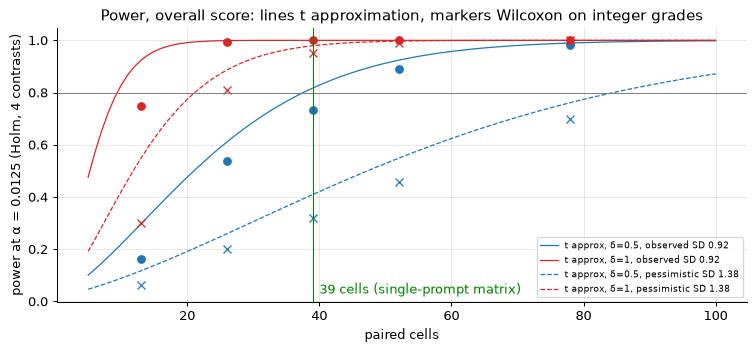

In [23]:
# Power curves: closed form (lines) and the simulation (points) for the overall score, r = 1, k = 1.
if not power.empty:
    fig, ax = plt.subplots(figsize=(8.5, 4))
    ns = np.arange(5, 101)
    for scen, ls in (("observed", "-"), ("pessimistic", "--")):
        sd = power_inputs[("overall_score", scen)]["sd_diff_r1k1"]
        for delta, c in ((0.5, "#1f77b4"), (1.0, "#d62728")):
            ax.plot(ns, [stats.power_paired(n, delta, sd, ALPHA_HOLM) for n in ns], ls=ls, color=c, lw=1,
                    label=f"t approx, δ={delta:g}, {scen} SD {sd:.2f}")
            pts = sim[(sim["metric"] == "overall_score") & (sim["scenario"] == scen) & (sim["reps"] == 1)
                      & (sim["gradings"] == 1) & (sim["delta"] == delta)]
            if len(pts):
                ax.plot(SIM_N, [pts.iloc[0][n] for n in SIM_N], "o" if scen == "observed" else "x", color=c)
    ax.axhline(0.8, color="gray", lw=0.8)
    ax.axvline(39, color="green", lw=0.8)
    ax.text(40, 0.03, "39 cells (single-prompt matrix)", color="green")
    ax.set_xlabel("paired cells")
    ax.set_ylabel(f"power at α = {ALPHA_HOLM} (Holm, 4 contrasts)")
    ax.set_title("Power, overall score: lines t approximation, markers Wilcoxon on integer grades")
    ax.legend(fontsize=7)
    fig.tight_layout()
    save(fig, "11_power_curves")

### Truthfulness events

For the share of sessions with an unsupported claim, the sample size needed to detect a change is far
larger. The cell below gives the cells per arm for a two-sided test (normal approximation, 80% power,
α = 0.05) from the demo round's base rate to a few alternatives. Read it as: rates this small are
**described with CIs**, not tested; a real difference would have to be large (e.g. single-prompt
inventing in a third of sessions) to show up in a round of affordable size.

In [24]:
base = float(df.groupby("run_id")["any_unsupported"].mean().mean())
z = stats._Z.inv_cdf(0.975) + stats._Z.inv_cdf(0.8)
tr = []
for alt in (0.01, 0.15, 0.25, 0.35):
    pbar = (base + alt) / 2
    n = math.ceil(z ** 2 * 2 * pbar * (1 - pbar) / (alt - base) ** 2)
    tr.append({"base_rate": round(base, 3), "alternative_rate": alt, "cells_per_arm": n})
pd.DataFrame(tr)

,base_rate,alternative_rate,cells_per_arm
0,0.064,0.01,194
1,0.064,0.15,201
2,0.064,0.25,60
3,0.064,0.35,32


## 11. Cost of candidate designs

The price of a round is, per arm, (new sessions x session cost) + (gradings x grading cost). Session
costs are the measured means for the multi-agent arms; for the single-prompt arms they are
**estimates** from the recovered token prices (section 7) for one call with about 6k input and 10k
output tokens (README section 7: a 4-7k token prompt and up to about 10k output tokens with reasoning).
A grading costs the measured `gpt-6.1-sol` mean. **An Anthropic grader's cost must be measured on a
pilot**; it is the parameter `GRADING_USD` and is not guessed here. The second-grader column is priced
at the same grading cost as a placeholder.

**Reuse.** The 39 cells of the staged matrix (`evals/matrix_ab_stage12.json`) already have multi-agent sessions in the
demo round (luna on all of them, terra on some). A design can reuse those sessions *and their
gradings* only if the app commit and the grader configuration are unchanged; with a new primary grader
they must be graded again (sessions reused, gradings not).

In [25]:
def call_usd(model, input_tokens=6000, output_tokens=10000):
    if model not in prices.index:
        return None
    p = prices.loc[model]
    return (input_tokens * p["usd_per_1M_input"] + output_tokens * p["usd_per_1M_output"]) / 1e6


SESSION_USD = {MA_LUNA: cost.loc[MA_LUNA, "session_usd"] if MA_LUNA in cost.index else None,
               MA_TERRA: cost.loc[MA_TERRA, "session_usd"] if MA_TERRA in cost.index else None,
               SP_LUNA: call_usd("gpt-6-luna"), SP_TERRA: call_usd("gpt-6.1-terra"), SP_SOL: call_usd("gpt-6.1-sol")}
GRADING_USD = float(df["eval_usd"].mean())  # gpt-6.1-sol, measured; replace with the chosen grader's pilot cost

ab_matrix = json.loads((ROOT / "evals" / "matrix_ab_stage12.json").read_text())["cases"]
sp_cells = {(c["persona"], c["ad"], c["input_set"], "default", c.get("work_preference") or "") for c in ab_matrix}
have = {a: len({load.cell_of(r) for r in rows if r["arm"] == a and r["rep"] == 1} & sp_cells) for a in (MA_LUNA, MA_TERRA)}
print(f"single-prompt matrix: {len(sp_cells)} cells; already run in the loaded data: "
      + ", ".join(f"{label(a)} {n}" for a, n in have.items()))


def design_cost(cells, arms_, reps=1, gradings=1, regrade_share=0.0, repeat_cells=0, second_grader_sessions=0,
                reuse_sessions=None, reuse_gradings=False):
    """Cost of one design. repeat_cells: cells that get one extra repeat in every arm (the noise-floor
    subset). reuse_sessions: {arm: sessions already run}; with reuse_gradings their gradings are reused too."""
    reuse_sessions = reuse_sessions or {}
    per_arm = cells * reps + repeat_cells
    new = {a: max(0, per_arm - reuse_sessions.get(a, 0)) for a in arms_}
    graded = {a: (new[a] if reuse_gradings else per_arm) for a in arms_}
    sessions_usd = sum(n * SESSION_USD[a] for a, n in new.items())
    grading_usd = sum(graded.values()) * gradings * GRADING_USD
    regrade_usd = per_arm * len(arms_) * regrade_share * GRADING_USD
    second_usd = second_grader_sessions * GRADING_USD
    return {"cells": cells, "arms": len(arms_), "reps": reps, "repeat_cells": repeat_cells, "gradings": gradings,
            "sessions": per_arm * len(arms_), "new_sessions": sum(new.values()), "sessions_usd": sessions_usd,
            "grading_usd": grading_usd, "regrade_usd": regrade_usd, "second_grader_usd": second_usd,
            "total_usd": sessions_usd + grading_usd + regrade_usd + second_usd}


ALL5 = [MA_LUNA, MA_TERRA, SP_LUNA, SP_TERRA, SP_SOL]
STEP1 = [MA_LUNA, SP_LUNA, SP_SOL]
designs = {
    "A0 cheapest step 1: 39 cells x {MA luna, SP luna, SP sol}; MA luna sessions and sol gradings reused; "
    "10% re-graded; 2nd grader on 30":
        design_cost(39, STEP1, regrade_share=0.10, second_grader_sessions=30,
                    reuse_sessions={MA_LUNA: have[MA_LUNA]}, reuse_gradings=True),
    "A lean, staged step 1: 39 cells x {MA luna, SP luna, SP sol}; MA luna sessions reused, all graded anew; "
    "10 cells repeated; 15% re-graded; 2nd grader on 40":
        design_cost(39, STEP1, repeat_cells=10, regrade_share=0.15, second_grader_sessions=40,
                    reuse_sessions={MA_LUNA: have[MA_LUNA]}),
    "A+ step 2 (only if needed): + {MA terra, SP terra} on the same 39 cells, MA terra sessions reused":
        design_cost(39, [MA_TERRA, SP_TERRA], repeat_cells=10, regrade_share=0.15, second_grader_sessions=20,
                    reuse_sessions={MA_TERRA: have[MA_TERRA]}),
    "B satisfactory: 52 cells x 5 arms, r=1; 10 cells repeated; 20% re-graded; 2nd grader on 60":
        design_cost(52, ALL5, repeat_cells=10, regrade_share=0.20, second_grader_sessions=60),
    "C scientific: 78 cells x 5 arms, r=2, k=2; 2nd grader on every session":
        design_cost(78, ALL5, reps=2, gradings=2, second_grader_sessions=78 * 5 * 2),
}
dz = pd.DataFrame(designs).T
print("session cost per arm (USD):", {label(a): round(float(v), 4) for a, v in SESSION_USD.items() if v is not None},
      f"; one grading {GRADING_USD:.3f} USD")
dz.to_csv(TAB / "design_costs.csv")
dz.round(2)

single-prompt matrix: 39 cells; already run in the loaded data: MA luna 39, MA terra 17
session cost per arm (USD): {'MA luna': 0.0282, 'MA terra': 0.088, 'SP luna': 0.0056, 'SP terra': 0.056, 'SP sol': 0.112} ; one grading 0.125 USD


,cells,arms,reps,repeat_cells,gradings,sessions,new_sessions,sessions_usd,grading_usd,regrade_usd,second_grader_usd,total_usd
"A0 cheapest step 1: 39 cells x {MA luna, SP luna, SP sol}; MA luna sessions and sol gradings reused; 10% re-graded; 2nd grader on 30",39.0,3.0,1.0,0.0,1.0,117.0,78.0,4.59,9.75,1.46,3.75,19.55
"A lean, staged step 1: 39 cells x {MA luna, SP luna, SP sol}; MA luna sessions reused, all graded anew; 10 cells repeated; 15% re-graded; 2nd grader on 40",39.0,3.0,1.0,10.0,1.0,147.0,108.0,6.04,18.37,2.76,5.00,32.17
"A+ step 2 (only if needed): + {MA terra, SP terra} on the same 39 cells, MA terra sessions reused",39.0,2.0,1.0,10.0,1.0,98.0,81.0,5.56,12.25,1.84,2.50,22.15
"B satisfactory: 52 cells x 5 arms, r=1; 10 cells repeated; 20% re-graded; 2nd grader on 60",52.0,5.0,1.0,10.0,1.0,310.0,310.0,17.97,38.75,7.75,7.50,71.96
"C scientific: 78 cells x 5 arms, r=2, k=2; 2nd grader on every session",78.0,5.0,2.0,0.0,2.0,780.0,780.0,45.21,194.98,0.00,97.49,337.68


## 12. Open questions, next steps and recommendations

*Written from the demo round (2026-11-10: multi-agent luna vs terra, one `gpt-6.1-sol` grading per
session). The numbers quoted are this notebook's outputs above; re-check them when the data changes.*

### What the demo round says

- **Luna vs terra in the app:** on 19 paired cells terra is +0.21 overall (95% CI -0.16 to +0.63;
  6 better, 9 equal, 4 worse; Wilcoxon p = 0.42). No primary measure differs beyond its CI. The only
  CI that excludes zero is completeness (+0.39, CI +0.03 to +0.79), one of ten exploratory measures,
  so it is not a finding. Terra costs 3.1x per session. This is "no difference larger than about 0.6
  points", not proof of equality.
- **Repeats agree closely; arm pairs spread more.** The six repeat pairs gave *identical* overall
  grades (σ_within = 0 on 6 df) and 0.3-0.8 points on most sub-scores (1.2 on work arrangement), while
  luna-terra differences spread with σ_diff = 0.92 overall. Read literally, the arm x cell interaction
  dominates and more *cells* help more than repeats. The integer-grade simulation disagrees in part:
  averaging two sessions or two gradings smooths the 1-point rounding steps, and at 39 cells it lifts
  the power for 0.5 points from 0.74 to 0.95 (repeat) or 0.89 (re-grade). Which view is right depends
  on the interaction/noise split, which six pairs cannot pin down (open question 1).
- **Grader noise is unknown.** No session was graded twice, and there is only one grader.
- **Truthfulness events are rare:** 7 of 110 sessions had an unsupported claim (8 of 8,633 checked
  claims). Detecting a change from 6% to 15% would take about 200 cells per arm, so truthfulness is
  described with CIs plus the trap scripts, not tested.
- **ATS:** this round was graded with an earlier rubric (keyword lists and a pass likelihood). Raw
  keyword coverage then tracked the share of the ad's keywords the candidate could truthfully claim
  (Spearman 0.97), so it measured persona x ad, not the writer. The grader now gives one model-judged
  ATS score instead (section 8), which counts only requirements the candidate has and treats stuffing or
  unsupported keywords as a fault.

### Sample size (Wilcoxon, integer grades, Holm α = 0.0125, 80% power)

| target | 26 cells | 39 cells | 52 cells | 78 cells |
|---|---|---|---|---|
| overall, 1 point, observed SD | 0.99 | 1.00 | 1.00 | 1.00 |
| overall, 1 point, pessimistic SD (1.5x) | 0.81 | 0.95 | 0.99 | 1.00 |
| overall, 0.5 point, observed SD, r = 1 | 0.54 | 0.74 | 0.89 | 0.98 |
| overall, 0.5 point, observed SD, r = 2 | 0.79 | 0.95 | 0.99 | 1.00 |
| overall, 0.5 point, pessimistic SD, r = 2 | 0.24 | 0.41 | 0.54 | 0.80 |
| fit, 0.5 point, observed SD, r = 1 | 0.65 | 0.85 | 0.96 | 0.99 |
| visual layout, 0.5 point, observed SD, r = 1 | 0.32 | 0.49 | 0.68 | 0.88 |

The closed-form t-test gives the same picture: **41 cells** for 0.5 points (observed SD) and **13**
for 1 point; under the pessimistic SD, **88** and **24**.

### Open questions

1. How much of σ_diff is interaction (only more cells help) and how much is writer or grader noise
   (repeats and re-gradings help)? Repeats on about 10 cells per arm and re-gradings on 10-15% of
   sessions answer this.
2. Does a second grader (e.g. an Anthropic model) agree with `gpt-6.1-sol` on the **arm differences**,
   not only on levels? Until this is measured, every claim depends on one grader.
3. Is the interaction larger for single prompt vs app than for luna vs terra? The pessimistic
   scenario assumes 1.5x; the first single-prompt cells will show.
4. Does the grader favour longer or more polished documents? Single-prompt sol may write more.
   Record document lengths and check score against length within arms.
5. How often does single-prompt LaTeX fall back to the fixed layout? A fallback lowers
   `visual_layout` for reasons unrelated to the writing; report fallbacks separately (the manifest
   records them).
6. Do the arms differ most on weak inputs (`notes_only`, weak fit)? The single-prompt matrix leaves
   out `notes_only`, so the claim covers only the input sets it includes.

### Recommendations for the next round

1. **Pre-register** the four primary contrasts, the measures in priority order (invented content,
   fit, visual layout, overall), a truthfulness non-inferiority margin of -0.5, Holm across the
   contrasts, and the minimum detectable effect: **1 point**. Report smaller differences with CIs,
   not as findings. Treat everything else as exploratory.
2. **Cells:** the 39-cell single-prompt matrix (13 personas x primary ad x `all4`/`cv_only`/`no_cv`)
   is enough for 1-point differences under either SD (power at least 0.95). Grow it only if 0.5 points
   must be claimed and the pilot SD is close to the observed one. Then add a second repeat on the same
   39 cells for the arms concerned (power 0.95) before adding cells.
3. **Repeats:** r = 1 everywhere, plus r = 2 on about **10 cells per arm** to measure writer noise
   (the noise floor in plot 03).
4. **Grader:** use one primary grader for every arm and session, never mixed across arms. Re-grade
   **10-15% of sessions** with the same grader (`run_matrix --rescore 2` on a subset). Grade **at
   least 30-40 sessions, spread over all arms, with a second grader**, to show the arm differences
   do not depend on the grader. Keep the grader prompt, model and image resolution fixed for the whole
   round, and grade all arms interleaved in one batch so provider drift cannot line up with an arm.
5. **Record:** arm (`method`, writer model), cell keys, rep, grader model and grading name, grader
   prompt version or commit, app commit, cost, calls, minutes, tokens per model, LaTeX fallback flags
   (all recorded already). Add **document lengths** (words, pages), the grader's
   temperature or seed if the API exposes one, and a `results.csv` column with the grader's name.
6. **Reuse:** the multi-agent luna sessions of all 39 cells (and terra for 17) exist at commit
   `aa5bdb2`. Reuse them only if the app has not changed since. With a new primary grader, grade them
   again with the new arms.
7. **Truthfulness:** report rates with Wilson CIs, unsupported and stretched claims per 100 claims,
   and the trap-script outcomes. State the detectable effect honestly.

### Next steps

1. Run design **A0 or A** (section 11): 39 cells x {MA luna, SP luna, SP sol}, with a re-graded
   subset and a second-grader subset. Add the new folders to `ROUNDS` and re-run this notebook.
2. Recompute sections 5 and 10 with the measured repeat, re-grading and arm-pair SDs. Then decide
   whether 0.5-point claims need r = 2.
3. Add the terra arms (A+) only if step 1 leaves the architecture question open. If SP luna or SP
   sol is clearly level with or below MA luna on truthfulness and fit, SP terra adds little.